# Analysis of Relational Attention
The purpose of this notebook is to analyze the linear relational attention head trained in the `model_training.ipynb`.

## Imports

In [1]:
%cd ../../
%load_ext autoreload
%autoreload 2

/Users/ktmurray/Documents/GitHub/relational-attention


In [2]:
import numpy as np
import torch
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import seaborn as sns

from src.relational_attention.tasks import BlockComparisonDataset
from src.relational_attention.models import RelationalAttentionHead, AttentionClassifier
from src.relational_attention.training import evaluate_model

In [3]:
torch.manual_seed(42)

## Load model

In [4]:
checkpoint = torch.load("./data/linear_relational_attention_block_classifier_full.pt", map_location="cpu")

In [5]:
# Recreate the same architecture
model = AttentionClassifier(
    embed_dim=checkpoint["metadata"]["embed_dim"],
    head_dim=checkpoint["metadata"]["head_dim"],
    attn_cls=RelationalAttentionHead,
    context_size=checkpoint["metadata"]["context_size"],
    linear=True
)
model.load_state_dict(checkpoint["model_state"])
model.eval()

AttentionClassifier(
  (attn): RelationalAttentionHead(
    (W_q): Linear(in_features=6, out_features=6, bias=False)
    (W_k): Linear(in_features=6, out_features=6, bias=False)
  )
  (fc): Linear(in_features=24, out_features=1, bias=True)
)

## Visualize query, key, value matrices

In [6]:
attn_head = model.attn
Q_weights = attn_head.W_q.weight.data
K_weights = attn_head.W_k.weight.data
V_matrix = attn_head.V.data

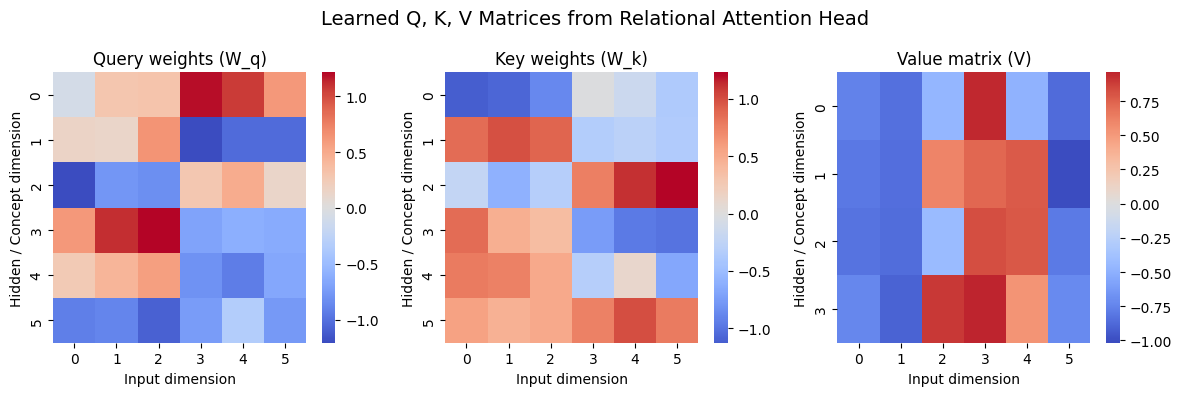

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.heatmap(Q_weights, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Query weights (W_q)")

sns.heatmap(K_weights, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Key weights (W_k)")

sns.heatmap(V_matrix, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Value matrix (V)")

for ax in axes:
    ax.set_xlabel("Input dimension")
    ax.set_ylabel("Hidden / Concept dimension")

plt.suptitle("Learned Q, K, V Matrices from Relational Attention Head", fontsize=14)
plt.tight_layout()
plt.show()

## Covariance structure of the matrices

In [8]:
def covariance(matrix):
    # subtract mean for proper covariance
    matrix_centered = matrix - matrix.mean(axis=0, keepdims=True)
    return np.cov(matrix_centered.T)  # (D, D)

In [9]:
cov_q = covariance(Q_weights)
cov_k = covariance(K_weights)
cov_v = covariance(V_matrix)

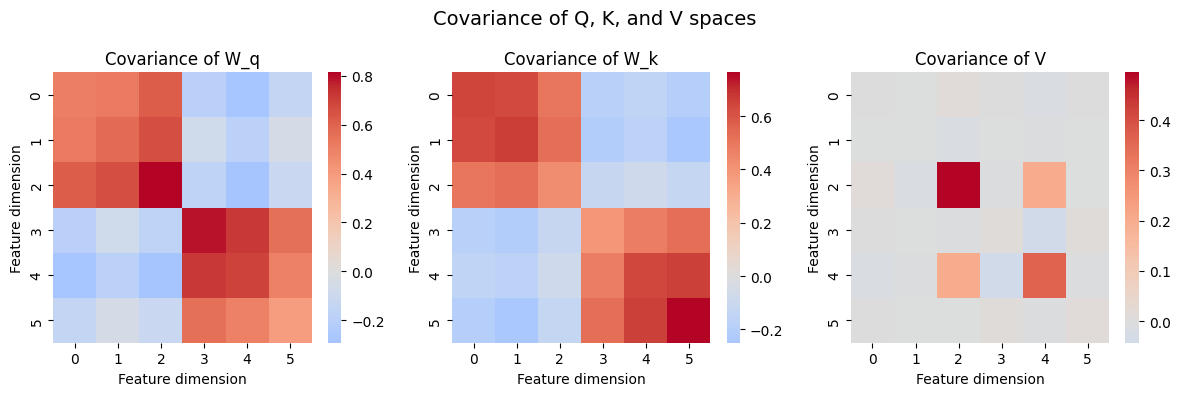

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.heatmap(cov_q, cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Covariance of W_q")

sns.heatmap(cov_k, cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Covariance of W_k")

sns.heatmap(cov_v, cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Covariance of V")

for ax in axes:
    ax.set_xlabel("Feature dimension")
    ax.set_ylabel("Feature dimension")

plt.suptitle("Covariance of Q, K, and V spaces", fontsize=14)
plt.tight_layout()
plt.savefig('./results/relational_attention_covariance.png')
plt.show()

- **Q–K subspaces** organize into structured, correlated blocks — indicating the model learns _block-level comparison spaces_ rather than raw input features.
    
- **V (value) matrix** is sparse and low-rank — encoding _relational prototypes_ rather than perceptual or block identities.
    
- High Q–K dot products → access the **“identity”** prototype in V; low dot products → access the **“non-identity”** prototype.
    
- The **attention mechanism** transforms similarity structure (Q–K alignments) into **discrete relational tokens** (“same” vs. “different”).
    
- The **linear decoder** simply checks for consistency among accessed value tokens — if all are identical → “same block”; if any differ → “different blocks.”

## Geometric interpretation

### Construct task

In [11]:
# Parameters
num_samples = 1000
num_vectors = 4
vector_len = 6

In [12]:
dataset = BlockComparisonDataset(num_samples, num_vectors, vector_len)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

In [13]:
dataset.data[0], dataset.labels[0]

(tensor([[1., 0., 0., 0., 0., 0.],
         [1., 0., 0., 0., 0., 0.],
         [1., 0., 0., 0., 0., 0.],
         [0., 0., 1., 0., 0., 0.]]),
 tensor(1.))

In [14]:
dataset.data[2], dataset.labels[2]

(tensor([[0., 0., 0., 0., 1., 0.],
         [0., 0., 0., 0., 1., 0.],
         [0., 0., 0., 0., 0., 1.],
         [1., 0., 0., 0., 0., 0.]]),
 tensor(0.))

In [15]:
acc_linear_relat = evaluate_model(model, loader)
print("Linear Relational attention:", acc_linear_relat)

Linear Relational attention: 1.0


### Understand how task input indexes query and keys

In [16]:
model.attn.W_q(dataset.data[0])

tensor([[-0.0869,  0.1498, -1.2049,  0.6100,  0.2578, -0.9121],
        [-0.0869,  0.1498, -1.2049,  0.6100,  0.2578, -0.9121],
        [-0.0869,  0.1498, -1.2049,  0.6100,  0.2578, -0.9121],
        [ 0.3139,  0.6457, -0.8260,  1.2131,  0.5757, -1.0884]],
       grad_fn=<MmBackward0>)

In [17]:
model.attn.W_k(dataset.data[0])

tensor([[-1.1274,  0.8560, -0.2292,  0.8561,  0.7862,  0.5627],
        [-1.1274,  0.8560, -0.2292,  0.8561,  0.7862,  0.5627],
        [-1.1274,  0.8560, -0.2292,  0.8561,  0.7862,  0.5627],
        [-0.8714,  0.8984, -0.3176,  0.3744,  0.5084,  0.5214]],
       grad_fn=<MmBackward0>)

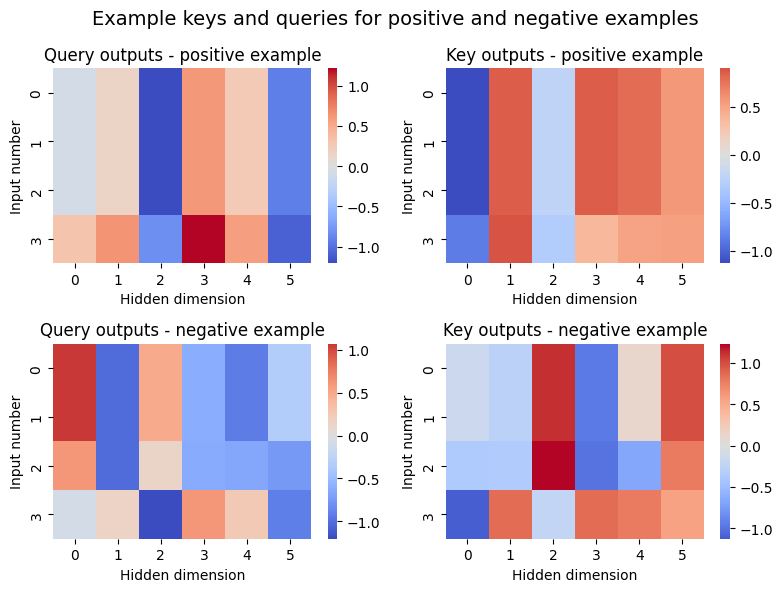

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
sns.heatmap(model.attn.W_q(dataset.data[0]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[0,0])
axes[0,0].set_title("Query outputs - positive example")

sns.heatmap(model.attn.W_k(dataset.data[0]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[0,1])
axes[0,1].set_title("Key outputs - positive example")

sns.heatmap(model.attn.W_q(dataset.data[2]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[1,0])
axes[1,0].set_title("Query outputs - negative example")

sns.heatmap(model.attn.W_k(dataset.data[2]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[1,1])
axes[1,1].set_title("Key outputs - negative example")

for ax_ in axes:
    for ax in ax_:
        ax.set_xlabel("Hidden dimension")
        ax.set_ylabel("Input number")

plt.suptitle("Example keys and queries for positive and negative examples", fontsize=14)
plt.tight_layout()
plt.show()

## Understand how attention weights are created

In [19]:
Q = model.attn.W_q(dataset.data[0])
K = model.attn.W_k(dataset.data[0])
attn_weights_pos = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
attn_weights_pos.shape

torch.Size([4, 4])

In [20]:
Q = model.attn.W_q(dataset.data[2])
K = model.attn.W_k(dataset.data[2])
attn_weights_neg = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
attn_weights_neg.shape

torch.Size([4, 4])

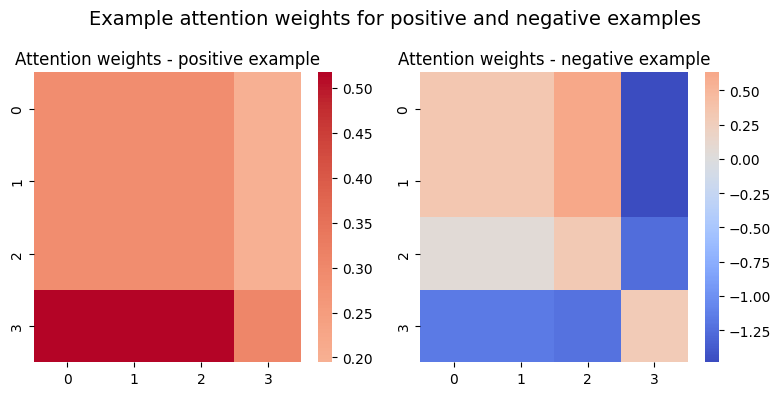

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.heatmap(attn_weights_pos.detach().numpy(), cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Attention weights - positive example")

sns.heatmap(attn_weights_neg.detach().numpy(), cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Attention weights - negative example")

plt.suptitle("Example attention weights for positive and negative examples", fontsize=14)
plt.tight_layout()
plt.show()

## Visualize how attention weights index on to values

In [22]:
out_positive = attn_weights_pos@V_matrix
out_positive.shape

torch.Size([4, 6])

In [23]:
out_negative = attn_weights_neg@V_matrix
out_negative.shape

torch.Size([4, 6])

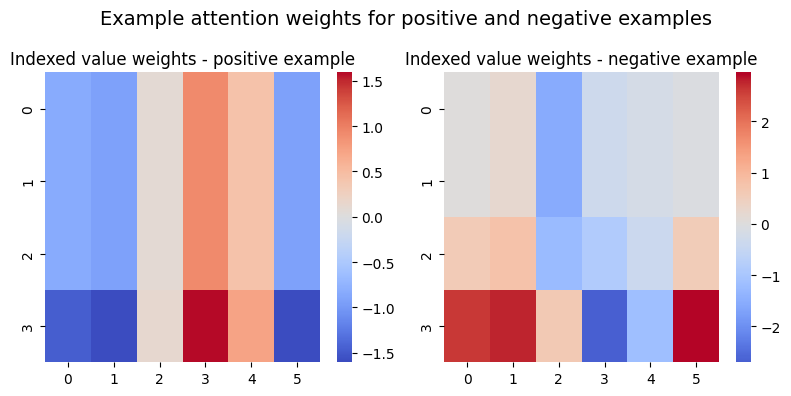

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
sns.heatmap(out_positive.detach().numpy(), cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Indexed value weights - positive example")

sns.heatmap(out_negative.detach().numpy(), cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Indexed value weights - negative example")

plt.suptitle("Example attention weights for positive and negative examples", fontsize=14)
plt.tight_layout()
plt.show()

## Let's understand what a positive example from the other block looks like

In [25]:
dataset.data[1], dataset.labels[1]

(tensor([[0., 0., 0., 1., 0., 0.],
         [0., 0., 0., 0., 1., 0.],
         [0., 0., 0., 0., 0., 1.],
         [0., 0., 0., 0., 1., 0.]]),
 tensor(1.))

In [26]:
Q = model.attn.W_q(dataset.data[1])
K = model.attn.W_k(dataset.data[1])
attn_weights_block2 = torch.matmul(Q, K.transpose(-2, -1)) / (K.size(-1) ** 0.5)  # (B, L, L)
attn_weights_block2.shape

torch.Size([4, 4])

In [27]:
out_block2 = attn_weights_block2@V_matrix
out_block2.shape

torch.Size([4, 6])

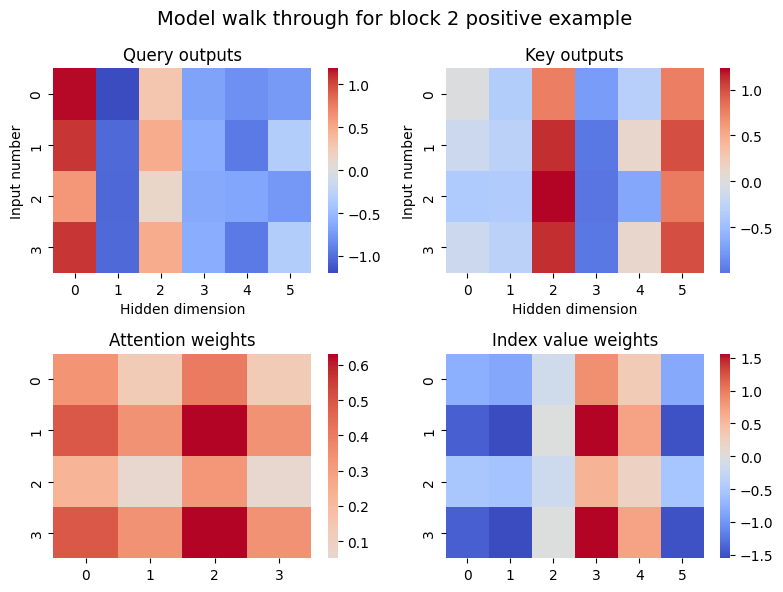

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
sns.heatmap(model.attn.W_q(dataset.data[1]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[0,0])
axes[0,0].set_title("Query outputs")
axes[0,0].set_xlabel("Hidden dimension")
axes[0,0].set_ylabel("Input number")

sns.heatmap(model.attn.W_k(dataset.data[1]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[0,1])
axes[0,1].set_title("Key outputs")
axes[0,1].set_xlabel("Hidden dimension")
axes[0,1].set_ylabel("Input number")

sns.heatmap(attn_weights_block2.detach().numpy(), cmap="coolwarm", center=0, ax=axes[1,0])
axes[1,0].set_title("Attention weights")

sns.heatmap(out_block2.detach().numpy(), cmap="coolwarm", center=0, ax=axes[1,1])
axes[1,1].set_title("Index value weights")

plt.suptitle("Model walk through for block 2 positive example", fontsize=14)
plt.tight_layout()
plt.show()

In [29]:
model.attn.W_q(dataset.data[1])[0].shape

torch.Size([6])

In [30]:
model.attn.W_k(dataset.data[1])[0].shape

torch.Size([6])

In [31]:
torch.sum(model.attn.W_q(dataset.data[1])[0]*model.attn.W_k(dataset.data[1])[0]) / (K.size(-1) ** 0.5)

tensor(0.3320, grad_fn=<DivBackward0>)

In [32]:
attn_weights_block2[0,0]

tensor(0.3320, grad_fn=<SelectBackward0>)

## How do attention weights map to value weights

In [33]:
attn_weights_block2@V_matrix[:,[2,4]]

tensor([[-0.1435,  0.3214],
        [ 0.0020,  0.7011],
        [-0.1683,  0.2128],
        [ 0.0020,  0.7011]], grad_fn=<MmBackward0>)

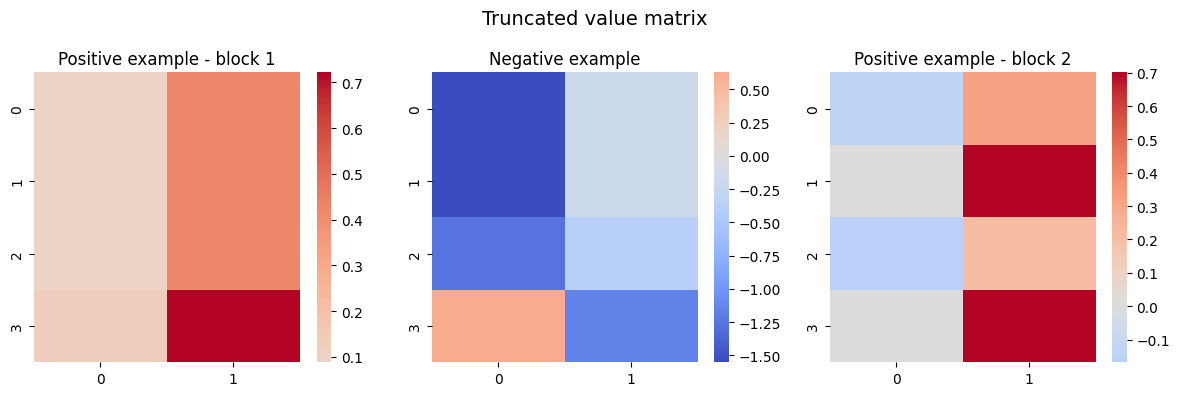

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
sns.heatmap((attn_weights_pos@V_matrix[:,[2,4]]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Positive example - block 1")

sns.heatmap((attn_weights_neg@V_matrix[:,[2,4]]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Negative example")

sns.heatmap((attn_weights_block2@V_matrix[:,[2,4]]).detach().numpy(), cmap="coolwarm", center=0, ax=axes[2])
axes[2].set_title("Positive example - block 2")

plt.suptitle("Truncated value matrix", fontsize=14)
plt.tight_layout()
plt.show()